# ATUS 2024: сон и бюджет времени работающих взрослых

**Исследовательский вопрос:** Как различается продолжительность сна в будни и выходные у работающих взрослых в США?

**Данные:** `atussum_2024.csv` и `atusresp_2024.csv`.

**План исследования:** загрузка и проверка данных → объединение таблиц → отбор работающих взрослых → описательная статистика → сравнение по полу, возрасту и типу занятости → дни недели → сон и рабочая активность → бюджет времени → вывод.

Сравниваются **разные респонденты**: каждый участник заполнил только один дневник. Результаты являются описательными, без сложных статистических тестов.

**Выполнили:** Окулова Александра (пара в сб 8.00) и Евстафьева Вера (пара в сб 9.45)

## 1. Импорт библиотек

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)

## 2. Загрузка и просмотр данных

In [19]:
summary = pd.read_csv("atussum_2024.csv")
respondents = pd.read_csv("atusresp_2024.csv")

print("Размер таблицы Summary:", summary.shape)
print("Размер таблицы Respondents:", respondents.shape)

print("\nSummary (первые 5 строк):")
display(summary[["TUCASEID", "TUDIARYDAY", "TEAGE", "TELFS", "t010101"]].head())

print("\nRespondents (первые 5 строк):")
display(respondents[["TUCASEID", "TUMONTH", "TEABSRSN", "TEERN", "TULINENO"]].head())

Размер таблицы Summary: (7669, 396)
Размер таблицы Respondents: (7669, 175)

Summary (первые 5 строк):


,TUCASEID,TUDIARYDAY,TEAGE,TELFS,t010101
0,20240101240005,3,29,1,540
1,20240101240020,6,77,5,480
2,20240101240098,1,19,1,680
3,20240101240107,1,23,1,180
4,20240101240123,5,22,1,470



Respondents (первые 5 строк):


,TUCASEID,TUMONTH,TEABSRSN,TEERN,TULINENO
0,20240101240005,1,-1,-1,1
1,20240101240020,1,-1,-1,1
2,20240101240098,1,-1,-1,1
3,20240101240107,1,-1,-1,1
4,20240101240123,1,-1,-1,1


На данном этапе загружены две исходные таблицы ATUS 2024, содержащие по 7 669 записей: Summary (396 признаков) и Respondents (175 признаков). Вывод первых строк показывает, что таблицы идеально сопоставимы по ключу TUCASEID. Так, таблица Summary содержит детальные данные о самом дневнике (день недели TUDIARYDAY, возраст, статус занятости и минуты сна t010101), а таблица Respondents дополняет их контекстной информацией об опросе (месяц TUMONTH) и образованием (TEABSRSN, TEERN). Значения -1 в таблице Respondents ожидаемы: в ATUS они обозначают неприменимые вопросы (например, уровень образования для слишком юных участников), что важно учитывать при дальнейшей обработке.

### 3. Проверка данных

Проверим, нет ли повторяющихся идентификаторов и пропусков в основных столбцах.

In [20]:
columns = ["TUCASEID", "TUFINLWGT", "TUDIARYDAY", "TEAGE", "TESEX", "TELFS", "TRDPFTPT", "t010101"]
print("Дубликаты ID в Summary:", summary["TUCASEID"].duplicated().sum())
print("Дубликаты ID в Respondents:", respondents["TUCASEID"].duplicated().sum())
print("Пропуски по основным столбцам:")
print(summary[columns].isna().sum().to_string())

Дубликаты ID в Summary: 0
Дубликаты ID в Respondents: 0
Пропуски по основным столбцам:
TUCASEID      0
TUFINLWGT     0
TUDIARYDAY    0
TEAGE         0
TESEX         0
TELFS         0
TRDPFTPT      0
t010101       0


## 4. Объединение таблиц

Объединяем таблицы по `TUCASEID`. Из `Respondents` добавляем месяц дневника (`TUMONTH`); основные поля для расчётов уже содержатся в `Summary`.

In [21]:
df = summary.merge(
    respondents[["TUCASEID", "TUMONTH"]],
    on="TUCASEID", how="inner", validate="one_to_one"
)
print("Строк после объединения:", len(df))

display(df[["TUCASEID", "TUMONTH", "TUDIARYDAY", "TEAGE", "TELFS", "t010101"]].head())

Строк после объединения: 7669


,TUCASEID,TUMONTH,TUDIARYDAY,TEAGE,TELFS,t010101
0,20240101240005,1,3,29,1,540
1,20240101240020,1,6,77,5,480
2,20240101240098,1,1,19,1,680
3,20240101240107,1,1,23,1,180
4,20240101240123,1,5,22,1,470


## 5. Отбор работающих взрослых

Берём людей **18 лет и старше** со статусом занятости `TELFS = 1` или `2` (работает или временно отсутствует на работе). В ATUS воскресенье имеет код `1`, суббота — `7`; остальные дни считаем буднями.

` t010101 ` — минуты сна за сутки. Переведём их в часы.

In [22]:
df = df[(df["TEAGE"] >= 18) & (df["TELFS"].isin([1, 2]))].copy()
df = df.dropna(subset=["TUFINLWGT", "TUDIARYDAY", "t010101"])
df = df[(df["TUFINLWGT"] > 0) & df["t010101"].between(0, 1440)].copy()

df["day_type"] = np.where(df["TUDIARYDAY"].isin([1, 7]), "Выходные", "Будни")
df["sleep_min"] = df["t010101"]
df["sleep_hours"] = df["sleep_min"] / 60

order = ["Будни", "Выходные"]
print("Работающих взрослых в выборке:", len(df))
print(df["day_type"].value_counts().reindex(order).to_string())

Работающих взрослых в выборке: 4347
day_type
Будни       2153
Выходные    2194


## 6. Описательная статистика сна

Посчитаем **число наблюдений, среднее, медиану, стандартное отклонение, минимум, максимум и квартильные значения (25% и 75%)**. Так мы увидим не только среднюю длительность сна, но и разброс.

Для основного сравнения также используем **взвешенное среднее**: итоговый вес `TUFINLWGT` учитывает особенности формирования выборки ATUS. Остальные показатели в таблице ниже — обычные, без весов. Сон измеряется в часах.

In [23]:
statistics = df.groupby("day_type")["sleep_hours"].agg(
    n="count", mean="mean", median="median", std="std",
    min="min", q25=lambda x: x.quantile(0.25),
    q75=lambda x: x.quantile(0.75), max="max"
).reindex(order)

def weighted_stats(group):
    vals = group["sleep_hours"].values
    w = group["TUFINLWGT"].values
    sorted_indices = np.argsort(vals)
    vals_sorted = vals[sorted_indices]
    w_sorted = w[sorted_indices]

    w_mean = np.average(vals, weights=w)

    cum_w = np.cumsum(w_sorted)
    w_median = vals_sorted[np.searchsorted(cum_w, cum_w[-1] / 2.0)]
    w_q25 = vals_sorted[np.searchsorted(cum_w, cum_w[-1] * 0.25)]
    w_q75 = vals_sorted[np.searchsorted(cum_w, cum_w[-1] * 0.75)]

    w_var = np.average((vals - w_mean)**2, weights=w)
    return pd.Series({
        "mean": w_mean, "median": w_median, "std": np.sqrt(w_var),
        "min": vals.min(), "q25": w_q25, "q75": w_q75, "max": vals.max()
    })

stats_weighted = df.groupby("day_type").apply(weighted_stats, include_groups=False).reindex(order)

print("Описательная статистика сна (часы):\n")
print("Без учёта весов:")
display(statistics.round(2))

print("\nС учётом весов:")
display(stats_weighted.round(2))

weighted_sleep = stats_weighted["mean"]

for day in order:
    print(f"{day}: {weighted_sleep[day] * 60:.1f} мин = {weighted_sleep[day]:.2f} ч")

difference = weighted_sleep["Выходные"] - weighted_sleep["Будни"]
print(f"Разница: {difference * 60:.1f} минуты (выходные минус будни)")

Описательная статистика сна (часы):

Без учёта весов:


,n,mean,median,std,min,q25,q75,max
day_type,,,,,,,,
Будни,2153,8.34,8.17,1.92,0.0,7.25,9.25,23.90
Выходные,2194,9.35,9.33,2.19,0.0,8.00,10.50,19.92



С учётом весов:


,mean,median,std,min,q25,q75,max
day_type,,,,,,,
Будни,8.44,8.25,2.09,0.0,7.25,9.42,23.90
Выходные,9.42,9.42,2.38,0.0,8.00,10.75,19.92


Будни: 506.5 мин = 8.44 ч
Выходные: 565.2 мин = 9.42 ч
Разница: 58.7 минуты (выходные минус будни)


В данном блоке рассчитывается описательная статистика продолжительности сна, причем расчет ведется в двух вариантах: без учета весов и с их применением. Вес (TUFINLWGT) — это статистический коэффициент, который показывает, какое количество людей в генеральной совокупности США представляет данный конкретный респондент из выборки (так как ATUS — это не перепись, а опрос).

Игнорирование весов (верхняя таблица) дает искаженную картину, если в выборке непропорционально много людей определенного возраста или пола; взвешенный расчет (нижняя таблица) корректирует это, делая выводы репрезентативными для всей страны. Сравнение таблиц показывает, что с учетом весов средний сон немного сдвигается вверх (до 8.44 ч в будни и 9.42 ч в выходные), а взвешенная медиана в выходные достигает 9.42 ч. При этом квартильные значения (25% и 75%) и максимальные показатели демонстрируют широкий разброс, а разница между буднями и выходными составляет 58.7 минуты дополнительного сна.

## 7. Графики сна

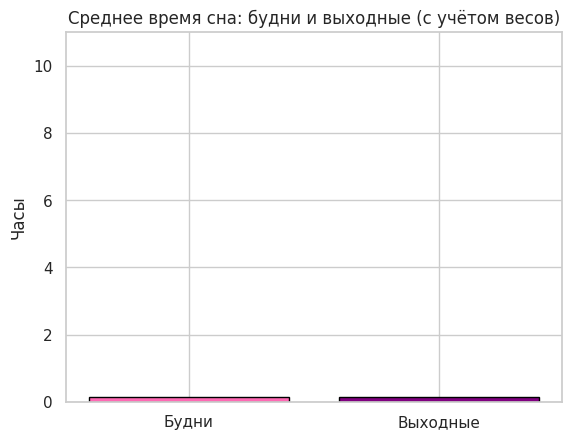

In [24]:
colors = ['hotpink', 'purple']
plt.bar(order, [weighted_sleep[day] / 60 for day in order],
        color=colors, edgecolor='black')
plt.ylabel("Часы")
plt.title("Среднее время сна: будни и выходные (с учётом весов)")
plt.ylim(0, 11)
plt.show()

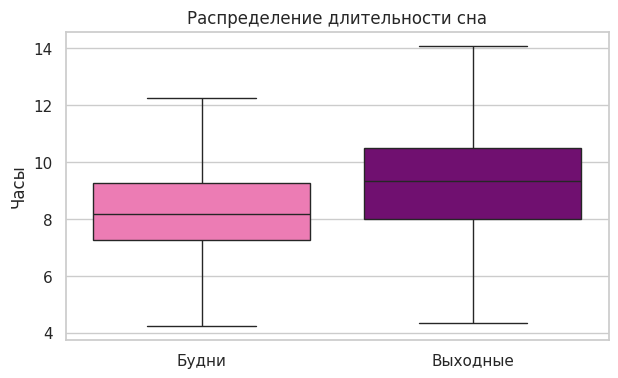

In [25]:
plt.figure(figsize=(7, 4))
sns.boxplot(
    data=df,
    x="day_type",
    y="sleep_hours",
    order=order,
    showfliers=False,
    hue="day_type",
    palette=['hotpink', 'purple'],
    legend=False
)
plt.xlabel("")
plt.ylabel("Часы")
plt.title("Распределение длительности сна")
plt.show()

На диаграмме среднего времени сна наглядно видно различие во взвешенных средних значениях: в выходные дни работающие взрослые в среднем спят почти на час дольше (около 9.4 часов), чем в будни (около 8.4 часов).

Боксплот подтверждает эту тенденцию и показывает более детальное распределение. Мы видим, что в выходные не только сдвигается вверх медиана, но и весь межквартильный диапазон расположен выше. При этом графики показывают, что разброс мнений достаточно велик: в обеих группах есть люди, которые спят как очень мало, так и очень много, но в выходные этот разброс смещен в сторону более продолжительного отдыха.

## 8. Подгруппы: пол, возраст и тип занятости

Проверим, сохраняется ли различие между буднями и выходными в разных подгруппах. В таблицах представлены **взвешенные средние** и количество респондентов. Это группировка и сравнение, а не доказательство причин различий.

### 8.1. Пол

In [26]:
df["sex"] = df["TESEX"].map({1: "Мужчины", 2: "Женщины"})
rows = []
for sex in ["Мужчины", "Женщины"]:
    row = {"Пол": sex}
    for day in order:
        group = df[(df["sex"] == sex) & (df["day_type"] == day)]
        row[f"{day}, n"] = len(group)
        row[f"{day}, ч"] = np.average(group["sleep_hours"], weights=group["TUFINLWGT"])
    row["Разница, мин"] = (row["Выходные, ч"] - row["Будни, ч"]) * 60
    rows.append(row)

display(pd.DataFrame(rows).set_index("Пол").round(2))

,"Будни, n","Будни, ч","Выходные, n","Выходные, ч","Разница, мин"
Пол,,,,,
Мужчины,1115,8.39,1119,9.41,61.30
Женщины,1038,8.50,1075,9.44,55.99


Разбивка данных по полу показывает, что паттерн «отсыпаться в выходные» характерен для обеих групп, однако у мужчин этот эффект выражен чуть сильнее: разница между сном в будни и выходные у них составляет 61.3 минуты против 56.0 минут у женщин.

### 8.2. Возраст

Разделим людей на возрастные группы с помощью `pd.cut()` и сравним взвешенную длительность сна в каждой группе. Внутри каждого возрастного интервала будни и выходные по-прежнему представлены разными людьми.

In [27]:
df["age_group"] = pd.cut(
    df["TEAGE"],
    bins=[18, 25, 35, 45, 55, 65, 120],
    right=False,
    labels=["18–24", "25–34", "35–44", "45–54", "55–64", "65+"]
)

age_rows = []
for age in df["age_group"].cat.categories:
    row = {"Возраст": age}
    for day in order:
        group = df[(df["age_group"] == age) & (df["day_type"] == day)]
        row[f"{day}, n"] = len(group)
        row[f"{day}, ч"] = np.average(group["sleep_hours"], weights=group["TUFINLWGT"])
    row["Разница, мин"] = (row["Выходные, ч"] - row["Будни, ч"]) * 60
    age_rows.append(row)

age_table = pd.DataFrame(age_rows).set_index("Возраст")
display(age_table.round(2))

,"Будни, n","Будни, ч","Выходные, n","Выходные, ч","Разница, мин"
Возраст,,,,,
18–24,128,9.01,133,10.21,71.96
25–34,435,8.61,435,9.46,51.19
35–44,545,8.26,524,9.28,60.93
45–54,409,8.35,414,9.30,56.94
55–64,396,8.18,419,9.38,71.96
65+,240,8.41,269,8.88,28.25


Анализ по возрастным группам показывает, что разница в продолжительности сна между выходными и буднями сохраняется во всех возрастах, но наиболее ярко она выражена у молодежи 18–24 лет и у людей предпенсионного возраста 55–64 лет (прибавка почти 72 минуты). При этом пожилые люди старше 65 лет спят в выходные относительно мало (8.88 ч), и разница с буднями у них минимальная — всего около 28 минут.

### 8.3. Тип занятости

`TRDPFTPT = 1` — полная занятость, `TRDPFTPT = 2` — неполная занятость. Здесь речь о **типе обычной занятости человека**, а не о том, работал ли он именно в день заполнения дневника.

In [28]:
df["employment_type"] = df["TRDPFTPT"].map({
    1: "Полная занятость", 2: "Неполная занятость"
})

employment_rows = []
for name in ["Полная занятость", "Неполная занятость"]:
    row = {"Тип занятости": name}
    for day in order:
        group = df[(df["employment_type"] == name) & (df["day_type"] == day)]
        row[f"{day}, n"] = len(group)
        row[f"{day}, ч"] = np.average(group["sleep_hours"], weights=group["TUFINLWGT"])
    row["Разница, мин"] = (row["Выходные, ч"] - row["Будни, ч"]) * 60
    employment_rows.append(row)

display(pd.DataFrame(employment_rows).set_index("Тип занятости").round(2))

,"Будни, n","Будни, ч","Выходные, n","Выходные, ч","Разница, мин"
Тип занятости,,,,,
Полная занятость,1758,8.34,1735,9.41,64.39
Неполная занятость,395,8.84,459,9.45,36.37


Анализ по типу занятости показывает, что сотрудники на полную ставку спят в будни меньше (8.34 ч), чем сотрудники на неполную ставку (8.84 ч), что логично объясняется большей рабочей нагрузкой. В выходные дни обе группы отсыпаются до примерно одного уровня (около 9.4 ч), однако из-за более глубокого дефицита сна в будни именно у полностью занятых людей разница между выходными и рабочими днями выражена значительно сильнее - почти 64.4 минуты против 36.4 минут у тех, кто работает неполный день.

## 9. Различия по конкретным дням недели

Рассчитаем число дневников и взвешенную среднюю продолжительность сна для **каждого дня отдельно**. Помним, что в каждом дне участвовали разные респонденты.

In [29]:
day_names = {
    1: "Воскресенье", 2: "Понедельник", 3: "Вторник", 4: "Среда",
    5: "Четверг", 6: "Пятница", 7: "Суббота"
}
day_codes = [2, 3, 4, 5, 6, 7, 1]
week_rows = []
for code in day_codes:
    group = df[df["TUDIARYDAY"] == code]
    avg_hours = np.average(group["sleep_hours"], weights=group["TUFINLWGT"])
    week_rows.append({
        "День": day_names[code],
        "Число дневников": len(group),
        "Взвешенное среднее, ч": avg_hours
    })
week_table = pd.DataFrame(week_rows).set_index("День")
display(week_table.round(2))

,Число дневников,"Взвешенное среднее, ч"
День,,
Понедельник,447,8.82
Вторник,431,8.38
Среда,454,8.35
Четверг,421,8.55
Пятница,400,8.10
Суббота,1063,9.09
Воскресенье,1131,9.74


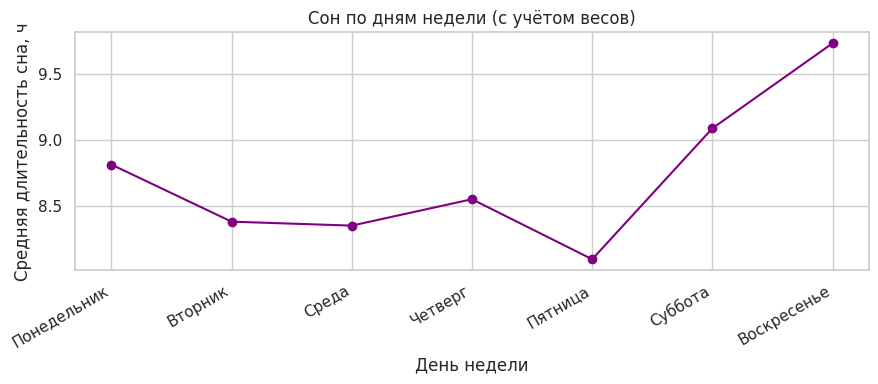

In [30]:
plt.figure(figsize=(9, 4))
plt.plot(week_table.index, week_table["Взвешенное среднее, ч"],
         marker="o",
         color="purple")
plt.ylabel("Средняя длительность сна, ч")
plt.xlabel("День недели")
plt.title("Сон по дням недели (с учётом весов)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

График динамики по дням недели наглядно демонстрирует классический паттерн накопления усталости: минимум сна приходится на пятницу (около 8.1 часа), что, вероятно, связано с завершением рабочей недели. Далее следует резкий скачок в субботу и пик отсыпания в воскресенье (почти 9.7 часа), после чего в понедельник показатели снова снижаются, так как люди возвращаются к рабочему графику.

## 10. Взаимосвязь сна с рабочей активностью в день дневника

В отличие от *типа занятости* выше, здесь рассматриваем, **сколько времени человек фактически посвятил работе и связанным с ней занятиям в день дневника**. Это не обязательно только оплачиваемая работа: категория также включает связанные с работой занятия.

In [31]:
work_columns = [col for col in summary.columns
                if col.startswith("t05") and len(col) == 7 and col[1:].isdigit()]
df["work"] = df[work_columns].sum(axis=1)
df["work_hours"] = df["work"] / 60
df["work_activity"] = np.where(df["work"] > 0, "Была работа", "Не было работы")

work_rows = []
for day in order:
    for status in ["Не было работы", "Была работа"]:
        group = df[(df["day_type"] == day) & (df["work_activity"] == status)]
        work_rows.append({
            "День": day,
            "Рабочая активность": status,
            "Число дневников": len(group),
            "Средний сон, ч (взв.)": np.average(group["sleep_hours"], weights=group["TUFINLWGT"])
        })
work_table = pd.DataFrame(work_rows)
display(work_table.round(2))

,День,Рабочая активность,Число дневников,"Средний сон, ч (взв.)"
0,Будни,Не было работы,406,9.64
1,Будни,Была работа,1747,8.14
2,Выходные,Не было работы,1534,9.77
3,Выходные,Была работа,660,8.67


Также посмотрим на **число часов работы** и продолжительность сна. Диаграмма рассеяния показывает каждый дневник одной точкой. Коэффициент корреляции Пирсона — простая численная характеристика линейной связи (от −1 до +1); здесь он рассчитан **без весов** и нужен только для описания выборки.

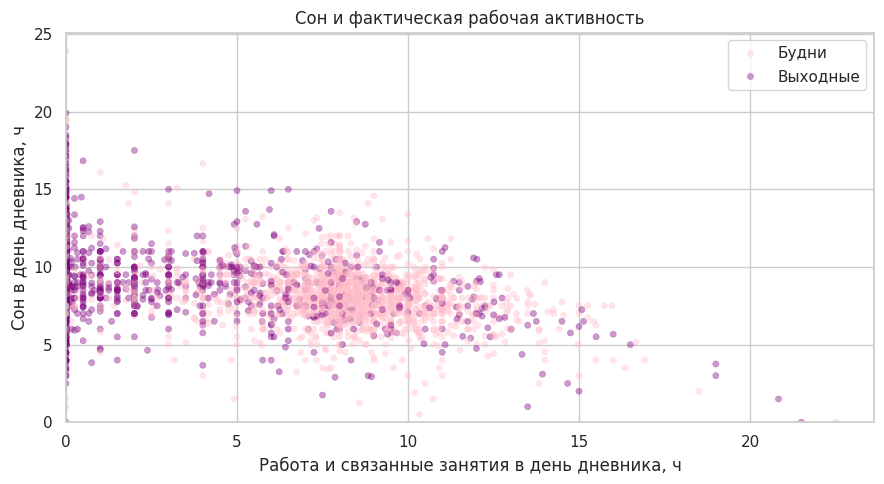

Будни: корреляция Пирсона = -0.36
Выходные: корреляция Пирсона = -0.30


In [32]:
plt.figure(figsize=(9, 5))
ax = sns.scatterplot(
    data=df, x="work_hours", y="sleep_hours", hue="day_type",
    hue_order=order, alpha=0.4, s=20, edgecolor=None,
    palette=['pink', 'purple']
)

ax.legend(title=None)

plt.xlabel("Работа и связанные занятия в день дневника, ч")
plt.ylabel("Сон в день дневника, ч")
plt.title("Сон и фактическая рабочая активность")
plt.xlim(left=0)
plt.ylim(bottom=0)
plt.tight_layout()
plt.show()

for day in order:
    group = df[df["day_type"] == day]
    r = group[["work_hours", "sleep_hours"]].corr().iloc[0, 1]
    print(f"{day}: корреляция Пирсона = {r:.2f}")

Диаграмма рассеяния демонстрирует заметную обратную связь между временем, потраченным на работу, и продолжительностью сна. Отрицательные коэффициенты корреляции (Пирсона):  -0.36 в будни и -0.30 в выходные, подтверждают, что чем больше часов человек посвящает рабочим обязанностям в течение дня, тем меньше времени у него остается на сон. При этом облако точек в будние дни (розовые) смещено вправо и вниз, что логично: в рабочие дни люди в среднем тратят значительно больше времени на работу и спят меньше, тогда как в выходные (фиолетовые точки) больше людей имеют нулевую рабочую активность и дольше спят.

## 11. Бюджет времени за сутки

Покажем, как распределяются 24 часа между сном, домашними делами, работой, досугом и прочими занятиями. Значения — взвешенные средние.

In [38]:
tcols = [col for col in summary.columns if col.startswith("t") and len(col) == 7 and col[1:].isdigit()]

for category, prefix in [("home", "02"), ("leisure", "12")]:
    selected_columns = [col for col in tcols if col[1:3] == prefix]
    df[category] = df[selected_columns].sum(axis=1)

df["other"] = 1440 - df[["sleep_min", "home", "work", "leisure"]].sum(axis=1)
assert (df["other"] >= 0).all()

names = {
    "sleep_min": "Сон", "home": "Домашние дела",
    "work": "Работа", "leisure": "Досуг", "other": "Прочее"
}
budget = pd.DataFrame(index=order)
for col, label in names.items():
    for day in order:
        group = df[df["day_type"] == day]
        budget.loc[day, label] = np.average(group[col], weights=group["TUFINLWGT"]) / 60

print("Среднее время занятий в часах:")
display(budget.round(2))

Среднее время занятий в часах:


,Сон,Домашние дела,Работа,Досуг,Прочее
Будни,8.44,1.45,6.36,3.13,4.62
Выходные,9.42,2.33,1.75,5.00,5.50


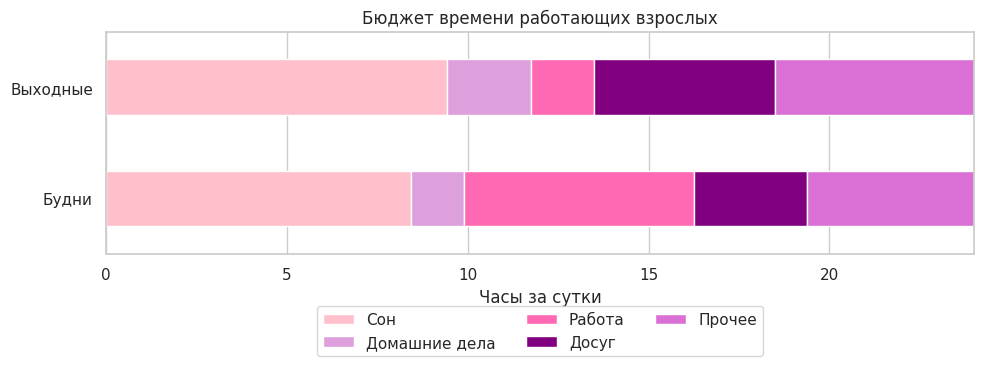

In [39]:
my_colors = {
    'Сон': 'pink',
    'Работа': 'hotpink',
    'Прочее': 'orchid',
    'Домашние дела': 'plum',
    'Досуг': 'purple'
}

ax = budget.plot(
    kind="barh",
    stacked=True,
    figsize=(10, 4),
    color=my_colors
)

ax.set_xlabel("Часы за сутки")
ax.set_ylabel("")
ax.set_xlim(0, 24)
ax.set_title("Бюджет времени работающих взрослых")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)

plt.tight_layout()
plt.show()

Диаграмма бюджета времени наглядно демонстрирует, как меняется структура суток в зависимости от дня недели. В будни основная часть бодрствования занята работой, а на сон, домашние дела и досуг отводится меньше времени. В выходные картина зеркально меняется: блок работы резко сокращается, при этом увеличивается время на сон, досуг и домашние дела, что отражает перераспределение 24 часов в пользу отдыха и личных занятий.

## 12. Итоговый вывод

**Ответ на исследовательский вопрос.** В выборке **4 347 работающих взрослых США** взвешенное среднее время сна составляет **около 8 ч 27 мин в будни** и **9 ч 25 мин в выходные**. Выходные превышают будни **примерно на 59 минут**.

**Что показали дополнительные сравнения:**

- **Описательная статистика:** медиана сна в выходные выше, а распределение сдвинуто в сторону большей продолжительности.
- **Пол:** и мужчины, и женщины в выходные в среднем спят дольше.
- **Возраст:** прибавка наблюдается во всех выделенных возрастных группах, но её величина различается.
- **Тип занятости:** среди работающих на полную ставку разница около **64 минут**, на неполную — около **36 минут**.
- **Конкретные дни:** больше всего сна по взвешенному среднему отмечено **в воскресенье** (около 9.4 ч), меньше всего — **в пятницу** (около 8 ч).
- **Рабочая активность:** среди людей с зарегистрированными рабочими занятиями сон в среднем короче, чем среди людей без таких занятий в день дневника. Чем больше рабочего времени указано в дневнике, тем обычно меньше времени остаётся на сон; это **наблюдаемая связь, а не доказательство причинности**.
- **Бюджет времени:** в выходные меньше времени отводится категории «Работа и связанные занятия» и больше — досугу и домашним делам.

**Ограничения:** один респондент — один дневник; будни и выходные сравниваются **между разными людьми**, а не внутри одного человека. Выходной по календарю не обязательно означает нерабочий день. Для расчёта официальных доверительных интервалов и проверки статистической значимости ATUS требуются дополнительные репликатные веса и соответствующая методика, поэтому здесь приводятся **описательные результаты**.

**Источник:** [ATUS 2024](https://www.bls.gov/tus/data/datafiles-2024.htm).